### Sales Growth Drivers: 2024 vs. 2025

Let's look at how sales changed across product subcategories from 2024 to 2025.

We want to understand what might be behind the growth: are customers buying more products, are they buying different things, or are discounts playing a role?

The dataset contains 14 categories, 49 subcategories, and just 100 distinct products. With only about two products per subcategory on average, the difference between analyzing subcategories and individual products is relatively small. I'll use subcategories as the main level of analysis, which provides a manageable level of detail without making the analysis unnecessarily granular.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
plt_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

In [2]:
input_file = "../data/dear_neighbour.xlsx"

sheets = pd.read_excel(input_file, sheet_name=None)
sheet_names = sheets.keys()

sheet_names

dict_keys(['fact_sales', 'dim_products', 'dim_stores', 'dim_customers', 'dim_suppliers'])

In [3]:
sales = sheets['fact_sales']
products = sheets['dim_products']

In [4]:
sales['year'] = sales['datetime'].dt.year

sales = (
    sales.merge(
        products[['product_id', 'category', 'subcategory', 'purchase_price_rub']],
        on='product_id',
        how='left'
    )
)

sales['unit_revenue'] = sales['line_total'] / sales['quantity']

sales['cost'] = sales['purchase_price_rub'] * sales['quantity']

sales['gross_profit'] = sales['line_total'] - sales['cost']

sales['gross_before_discount'] = sales['quantity'] * sales['unit_price']

sales['discount_amount'] = sales['gross_before_discount'] - sales['line_total']

sales['loyalty_receipts'] = sales.loc[sales['customer_id'].notna(), 'receipt_id']

In [5]:
summary_by_subcategory = (
    sales
    .groupby(['year', 'subcategory'])
    .agg(
        revenue=('line_total', 'sum'),
        gross_profit=('gross_profit', 'sum'),
        costs=('cost', 'sum'),
        avg_receipt_value=('line_total', 'mean'),
        units_sold=('quantity', 'sum'),
        receipts=('receipt_id', 'nunique'),
        loyalty_receipts=('loyalty_receipts', 'nunique'),
        gross_before_discount=('gross_before_discount', 'sum'),
        discount_amount=('discount_amount', 'sum'),
        avg_discount_percent=('discount_percent', 'mean'),
    )
)

In [6]:
summary_by_subcategory['gross_margin'] = (
        summary_by_subcategory['gross_profit']
        / summary_by_subcategory['revenue'].replace(0, np.nan)
)

summary_by_subcategory['revenue_per_unit'] = (
        summary_by_subcategory['revenue']
        / summary_by_subcategory['units_sold'].replace(0, np.nan)
)

summary_by_subcategory['revenue_share'] = (
    summary_by_subcategory['revenue']
    / summary_by_subcategory.groupby(level=['year'])['revenue'].transform('sum').replace(0, np.nan)
)

summary_by_subcategory['discount_share'] = (
    summary_by_subcategory['discount_amount']
    / summary_by_subcategory.groupby(level=['year'])['discount_amount'].transform('sum').replace(0, np.nan)
)

summary_by_subcategory['discount_share_of_profit'] = (
    summary_by_subcategory['discount_amount']
    / summary_by_subcategory['gross_profit'].replace(0, np.nan)
)

summary_by_subcategory['loyalty_receipts_share'] = (
    summary_by_subcategory['loyalty_receipts']
    / summary_by_subcategory.groupby(level=['year'])['loyalty_receipts'].transform('sum').replace(0, np.nan)
)

summary_by_subcategory['avg_units_per_receipt'] = (
    summary_by_subcategory['units_sold']
    / summary_by_subcategory['receipts'].replace(0, np.nan)
)

In [7]:
wide = summary_by_subcategory.unstack('year')

metrics = {
    'gross_profit_change': ('gross_profit', 'pct'),
    'gross_margin_change': ('gross_margin', 'pp'),
    'revenue_change': ('revenue', 'pct'),
    'units_sold_change': ('units_sold', 'pct'),
    'revenue_share_change': ('revenue_share', 'pp'),
    'discount_share_change': ('discount_share', 'pp'),
    'discount_percent_of_profit_change': ('discount_share_of_profit', 'pp'),
    'loyalty_receipts_share_change': ('loyalty_receipts_share', 'pp'),
    'revenue_per_unit_change': ('revenue_per_unit', 'pct'),
    'avg_receipt_value_change': ('avg_receipt_value', 'pct'),
    'avg_units_per_receipt_change': ('avg_units_per_receipt', 'pct'),
    'receipts_change': ('receipts', 'pct'),
}

subcategories_yoy = pd.DataFrame(index=wide.index)

for column, (metric, change_type) in metrics.items():
    old = wide[metric][2024]
    new = wide[metric][2025]

    if change_type == 'pct':
        change = 100 * (new - old) / old.replace(0, np.nan)
    elif change_type == 'pp':
        change = 100 * (new - old)
    else:
        change = new - old

    subcategories_yoy[column] = change

In [8]:
subcategories_yoy.sort_values('revenue_change', ascending=False, inplace=True)

In [9]:
def scatter_matrix_show(metrics, cols=2, width=10, row_height=2, y_min=None, y_max=None):
    rows = len(metrics) // cols + 1

    fig, axes = plt.subplots(rows, cols, figsize=(width, row_height * rows))

    for ax, (column, title, ylabel) in zip(axes.flat, metrics):
        ax.scatter(
            subcategories_yoy.index,
            subcategories_yoy[column],
            facecolors='none',
            edgecolors=plt_colors[0],
        )
        ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
        ax.set_title(title)
        ax.set_xlabel('Subcategory')
        ax.set_xticks([])
        ax.set_ylim(y_min, y_max)

    for ax in axes.flat[len(metrics):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()


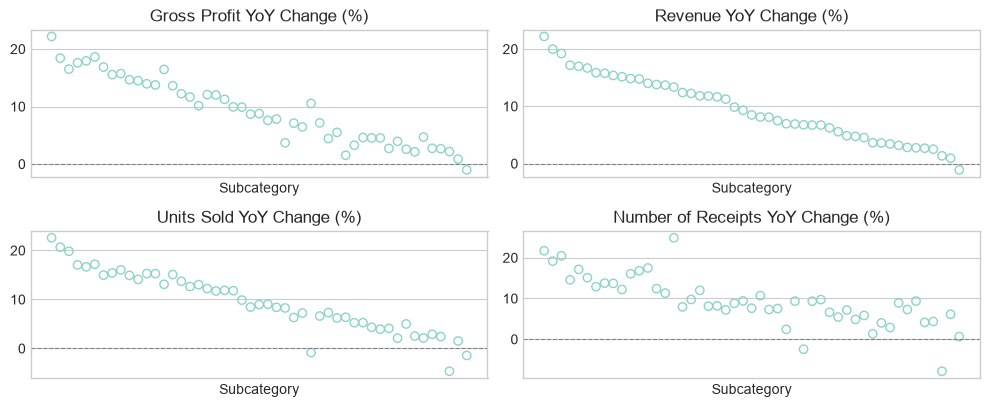

In [10]:
metrics = [
    ('gross_profit_change', 'Gross Profit YoY Change (%)', 'Change (%)'),
    ('revenue_change', 'Revenue YoY Change (%)', 'Change (%)'),
    ('units_sold_change', 'Units Sold YoY Change (%)', 'Change (%)'),
    ('receipts_change', 'Number of Receipts YoY Change (%)', 'Change (%)'),
]
scatter_matrix_show(metrics)

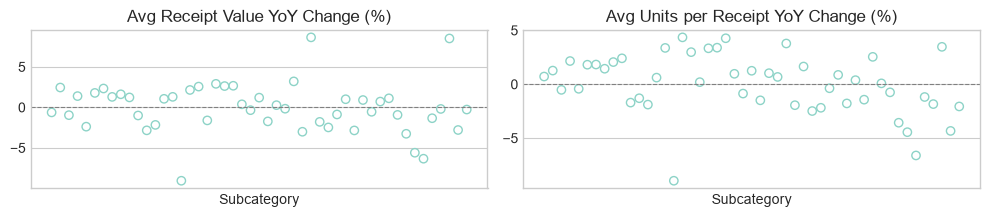

In [11]:
metrics = [
    ('avg_receipt_value_change', 'Avg Receipt Value YoY Change (%)', 'Change (%)'),
    ('avg_units_per_receipt_change', 'Avg Units per Receipt YoY Change (%)', 'Change (%)'),
]

scatter_matrix_show(metrics)

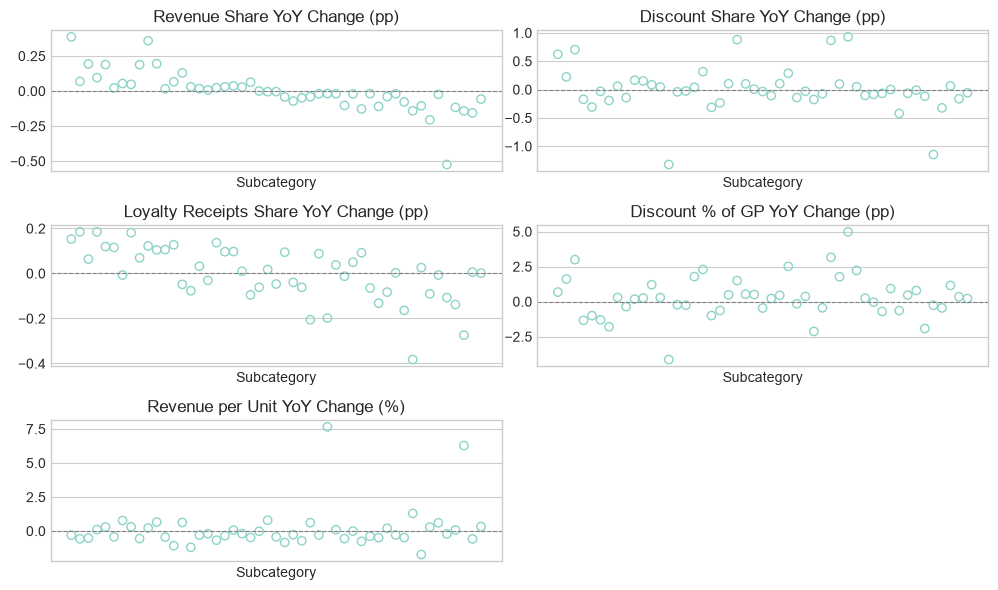

In [12]:
metrics = [
    ('revenue_share_change', 'Revenue Share YoY Change (pp)', 'Change (pp)'),
    ('discount_share_change', 'Discount Share YoY Change (pp)', 'Change (pp)'),
    ('loyalty_receipts_share_change', 'Loyalty Receipts Share YoY Change (pp)', 'Change (pp)'),
    ('discount_percent_of_profit_change', 'Discount % of GP YoY Change (pp)', 'Change (pp)'),
    ('revenue_per_unit_change', 'Revenue per Unit YoY Change (%)', 'Change (%)'),
]

scatter_matrix_show(metrics)

In [13]:
subcategories_yoy[subcategories_yoy['revenue_per_unit_change'] > 2.5]['revenue_per_unit_change']

subcategory
pasta          7.660326
cooking oil    6.288163
Name: revenue_per_unit_change, dtype: float64

In [14]:
subcategories_yoy[subcategories_yoy['avg_receipt_value_change'].abs() > 5]['avg_receipt_value_change']

subcategory
butter        -9.057918
pasta          8.638141
nuts          -5.600282
sour cream    -6.337953
cooking oil    8.502813
Name: avg_receipt_value_change, dtype: float64

In [15]:
summary_by_subcategory.xs('cooking oil', level='subcategory')['revenue_per_unit']

year
2024    329.882702
2025    350.626264
Name: revenue_per_unit, dtype: float64

In [16]:
summary_by_subcategory.xs('pasta', level='subcategory')['revenue_per_unit']

year
2024    108.447401
2025    116.754825
Name: revenue_per_unit, dtype: float64

Looks like the only thing built into it was general sales growth, without any more specific patterns.

Based on the variation we see across subcategories, sales growth seems to be driven mainly by an increase in the number of receipts. Since the average number of units per subcategory per receipt changes very little, more receipts naturally translate into more units sold. Most other year-on-year changes look more like random fluctuations than meaningful trends.

The composition of receipts also remains largely unchanged. We don't see any substantial shifts in the share of receipts from loyalty customers or in the average unit price within most subcategories.

There are two exceptions: cooking oil and pasta, where the average unit price rises quite sharply, leading to higher receipt values for these subcategories. However, neither shows any other unusual patterns, so these increases don't seem to be part of a broader change in purchasing behaviour.